# Benchmark & Load Testing Toàn Diện: Hệ Thống KTPM (Spring Boot 4 + MySQL 8)

Kịch bản kiểm thử tải tối đa (Comprehensive End-to-End Stress & Load Testing) trên môi trường Kaggle CPU:
- **Bao phủ 100% Endpoints hệ thống**:
  - `Auth`: Đăng ký tài khoản (`POST /auth/register`), Đăng nhập lấy JWT (`POST /auth/login`).
  - `Customers`: Phân trang danh sách (`GET /customers`), Chi tiết hồ sơ (`GET /customers/{id}`), Tạo mới (`POST /customers`), Cập nhật (`PUT /customers/{id}`), Lịch sử đơn hàng (`GET /customers/{id}/orders`).
  - `Products`: Phân trang (`GET /products`), Chi tiết (`GET /products/{id}`), **POST nhập hàng trùng tên (cộng dồn số lượng tồn kho & cập nhật giá bán mới)**, Cập nhật thông tin/giá (`PATCH /products/{id}`).
  - `Orders`: Phân trang (`GET /orders`), Chi tiết (`GET /orders/{id}`), Tạo đơn Hot Product tranh chấp cao (chống Overselling), Tạo đơn nhiều sản phẩm xáo trộn thứ tự (chống Deadlock), Cập nhật chu trình đơn hàng (`PENDING` -> `SHIPPING` -> `COMPLETED`), Hủy đơn hàng (`CANCELLED`) để hoàn kho.
  - `Users`: Lấy danh sách tài khoản người dùng (`GET /users` - yêu cầu quyền ADMIN).
  - `Security & Negative Testing`: Kiểm tra phân quyền bắt đúng `403 Forbidden` (User thường truy cập endpoint Admin), bắt `400 Bad Request` khi vượt tồn kho hoặc cập nhật sai trạng thái.
- **Mô phỏng 3 Persona người dùng chân thực chạy đồng thời**:
  1. **CustomerShopperUser (Trọng số 70%)**: Khách hàng mua sắm (tra cứu sản phẩm, xem hồ sơ, đặt đơn hàng hot, đặt đơn nhiều món, hủy đơn, kiểm tra bảo mật).
  2. **WarehouseAdminUser (Trọng số 20%)**: Quản trị kho & đơn hàng (nhập hàng cộng dồn, cập nhật sản phẩm, duyệt đơn qua từng trạng thái, quản lý users, sửa hồ sơ khách hàng).
  3. **FlashSaleSpammerUser (Trọng số 10%)**: Bot / Người săn sale gửi request liên tục với tần suất cực cao vào sản phẩm Hot (stress test cơ chế Pessimistic Locking `SELECT ... FOR UPDATE` và Lock Ordering).
- **Giám sát & Đo lường**:
  - Đo đạc chi tiết CPU (Total & Per-core), RAM (MB), Throughput (RPS), Latency (Median, P95, P99), Failure rate.
  - Kiểm tra tính nhất quán toàn vẹn cơ sở dữ liệu (Deep Data Consistency Verification): Tồn kho ban đầu + Tồn kho nhập thêm = Tồn kho còn lại + Tổng số lượng đã bán (tồn kho không âm, không thất thoát hàng hóa).

In [1]:
!apt-get update -qq
!apt-get install -y -qq openjdk-21-jdk mysql-server maven curl psmisc > /dev/null 2>&1
!update-alternatives --set java /usr/lib/jvm/java-21-openjdk-amd64/bin/java > /dev/null 2>&1
!update-alternatives --set javac /usr/lib/jvm/java-21-openjdk-amd64/bin/javac > /dev/null 2>&1
!pip install -q locust psutil requests pandas matplotlib pymysql

print("Java version:")
!java -version
print("\nMySQL version:")
!mysql --version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Java version:
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)

MySQL version:
mysql  Ver 8.0.46-0ubuntu0.24.04.4 for Linux on x86_64 ((Ubuntu))


In [2]:
import os
import shutil

repo_url = "https://github.com/24020196/BTL-KTPM.git"
project_dir = "/kaggle/working/project"

if os.path.exists(project_dir):
    shutil.rmtree(project_dir)

input_paths = [os.path.join(dp, f) for dp, dn, fn in os.walk("/kaggle/input") for f in fn if f == "pom.xml"]
if input_paths:
    src_folder = os.path.dirname(input_paths[0])
    shutil.copytree(src_folder, project_dir)
    print(f"Copied source code from Kaggle Input: {src_folder}")
else:
    !git clone {repo_url} {project_dir}

pom_dirs = [dp for dp, dn, fn in os.walk(project_dir) for f in fn if f == "pom.xml"]
backend_dir = pom_dirs[0] if pom_dirs else project_dir

os.chdir(backend_dir)
print("Working directory:", os.getcwd())
!ls -la

Cloning into '/kaggle/working/project'...
remote: Enumerating objects: 772, done.
remote: Counting objects: 100% (205/205), done.
remote: Compressing objects: 100% (109/109), done.
remote: Total 772 (delta 85), reused 138 (delta 64), pack-reused 567 (from 1)
Receiving objects: 100% (772/772), 1.10 MiB | 2.10 MiB/s, done.
Resolving deltas: 100% (299/299), done.
Working directory: /kaggle/working/project
total 344
drwxr-xr-x 6 root root   4096 Oct 29 08:34 .
drwxr-xr-x 4 root root   4096 Oct 29 08:34 ..
-rw-r--r-- 1 root root 241868 Oct 29 08:34 benchmark-load-testing-ktpm.ipynb
-rw-r--r-- 1 root root    912 Oct 29 08:34 docker-compose.yml
-rw-r--r-- 1 root root    284 Oct 29 08:34 Dockerfile
drwxr-xr-x 3 root root   4096 Oct 29 08:34 docs
-rw-r--r-- 1 root root     96 Oct 29 08:34 .env
-rw-r--r-- 1 root root     96 Oct 29 08:34 .env.example
drwxr-xr-x 8 root root   4096 Oct 29 08:34 .git
-rw-r--r-- 1 root root     38 Oct 29 08:34 .gitattributes
-rw-r--r-- 1 root root    473 Oct 29 08:34

In [3]:
import subprocess
import time

print("Starting MySQL service...")
subprocess.run(["service", "mysql", "start"], check=True)
time.sleep(2)

init_sql = """
DROP DATABASE IF EXISTS KTPM;
CREATE DATABASE IF NOT EXISTS KTPM CHARACTER SET utf8mb4 COLLATE utf8mb4_unicode_ci;
CREATE USER IF NOT EXISTS 'ktpm_app'@'localhost' IDENTIFIED BY '12345678';
GRANT ALL PRIVILEGES ON KTPM.* TO 'ktpm_app'@'localhost';
GRANT ALL PRIVILEGES ON KTPM.* TO 'root'@'localhost';
FLUSH PRIVILEGES;
"""

res = subprocess.run(["mysql", "-u", "root", "-e", init_sql], capture_output=True, text=True)
if res.returncode != 0:
    subprocess.run(["mysql", "-u", "root", "-p12345678", "-e", init_sql], capture_output=True, text=True)

subprocess.run([
    "mysql", "-u", "root", "-e",
    "ALTER USER 'root'@'localhost' IDENTIFIED WITH mysql_native_password BY '12345678'; FLUSH PRIVILEGES;"
], capture_output=True)

print("MySQL initialized: database KTPM ready.")

Starting MySQL service...
 * Starting MySQL database server mysqld


su: warning: cannot change directory to /nonexistent: No such file or directory


   ...done.
MySQL initialized: database KTPM ready.


In [4]:
import os

env_content = """DB_NAME=KTPM
DB_USERNAME=root
DB_PASSWORD=12345678
SPRING_DATASOURCE_URL=jdbc:mysql://localhost:3306/KTPM?createDatabaseIfNotExist=true&useSSL=false&serverTimezone=UTC&allowPublicKeyRetrieval=true
SPRING_DATASOURCE_USERNAME=root
SPRING_DATASOURCE_PASSWORD=12345678
SERVER_PORT=3000
JWT_SECRET=404E635266556A586E3272357538782F413F4428472B4B6250645367566B5970
JWT_EXPIRATION=86400000
"""

env_file_path = os.path.join(backend_dir, ".env")
with open(env_file_path, "w", encoding="utf-8") as f:
    f.write(env_content)

print("Created config file:", env_file_path)

Created config file: /kaggle/working/project/.env


In [5]:
import os
import subprocess

os.chdir(backend_dir)
!sed -i 's/\r$//' mvnw 2>/dev/null || true
!chmod +x mvnw

print("Building Spring Boot JAR...")
build_process = subprocess.run(["./mvnw", "clean", "package", "-DskipTests", "-B"], capture_output=True, text=True)

if build_process.returncode == 0:
    jars = [f for f in os.listdir("target") if f.endswith(".jar") and not f.endswith(".original") and not f.endswith("-sources.jar")]
    print(f"Build success! JAR: target/{jars[0]}")
else:
    print("Build failed! Log:")
    print(build_process.stdout[-2000:])
    print(build_process.stderr[-1000:])

Building Spring Boot JAR...
Build success! JAR: target/KTPM-0.0.1-SNAPSHOT.jar


In [6]:
locust_code = """import json
import random
import uuid
from locust import HttpUser, task, between, SequentialTaskSet

with open("/kaggle/working/bench_config.json", encoding="utf-8") as f:
    CONFIG = json.load(f)

ADMIN_TOKEN = CONFIG["admin_token"]
CUSTOMERS = CONFIG["customer_numbers"]
HOT_PRODUCT = CONFIG["hot_product"]
MULTI_PRODUCTS = CONFIG["multi_products"]
ALL_PRODUCTS = CONFIG["all_products"]


def is_out_of_stock(res):
    return res.status_code == 400 and ("tồn kho" in res.text or "kho" in res.text)


# ==============================================================================
# PERSONA 1: Khách hàng mua sắm (Customer Shopper Journey)
# ==============================================================================
class CustomerShopperJourney(SequentialTaskSet):
    def on_start(self):
        self.customer_id = random.choice(CUSTOMERS)
        self.product_id = HOT_PRODUCT
        self.created_order_id = None

    @task
    def browse_products(self):
        with self.client.get("/api/v1/products?page=0&size=10", headers=self.user.auth_headers,
                             name="01_GET_products_page", catch_response=True) as res:
            if res.status_code == 200:
                items = res.json().get("content", [])
                if items:
                    self.product_id = random.choice(items)["id"]
            else:
                res.failure(f"{res.status_code}: {res.text[:100]}")

    @task
    def view_product_detail(self):
        with self.client.get(f"/api/v1/products/{self.product_id}", headers=self.user.auth_headers,
                             name="02_GET_product_detail", catch_response=True) as res:
            if res.status_code not in (200, 404):
                res.failure(f"{res.status_code}: {res.text[:100]}")

    @task
    def view_customer_profile(self):
        with self.client.get(f"/api/v1/customers/{self.customer_id}", headers=self.user.auth_headers,
                             name="03_GET_customer_detail", catch_response=True) as res:
            if res.status_code != 200:
                res.failure(f"{res.status_code}: {res.text[:100]}")

    @task
    def view_customer_orders(self):
        with self.client.get(f"/api/v1/customers/{self.customer_id}/orders", headers=self.user.auth_headers,
                             name="04_GET_customer_orders", catch_response=True) as res:
            if res.status_code != 200:
                res.failure(f"{res.status_code}: {res.text[:100]}")

    @task
    def create_order_hot_product(self):
        if random.random() >= 0.70:
            return
        payload = {
            "customerNumber": self.customer_id,
            "items": [{"productCode": HOT_PRODUCT, "quantityOrdered": random.randint(1, 2)}]
        }
        with self.client.post("/api/v1/orders", json=payload, headers=self.user.auth_headers,
                              name="05_POST_orders_hot_product", catch_response=True) as res:
            if res.status_code == 201:
                self.created_order_id = res.json()["orderNumber"]
            elif is_out_of_stock(res):
                res.request_meta["name"] = "05_POST_orders_hot_out_of_stock"
                res.success()
            else:
                res.failure(f"{res.status_code}: {res.text[:100]}")

    @task
    def create_order_multi_product(self):
        if random.random() >= 0.50:
            return
        # Test Lock Ordering: xáo trộn thứ tự ID sản phẩm ngẫu nhiên để kích hoạt lock ordering chống deadlock
        items = [{"productCode": code, "quantityOrdered": random.randint(1, 2)} for code in MULTI_PRODUCTS]
        random.shuffle(items)
        payload = {"customerNumber": self.customer_id, "items": items}
        with self.client.post("/api/v1/orders", json=payload, headers=self.user.auth_headers,
                              name="06_POST_orders_multi_product", catch_response=True) as res:
            if res.status_code == 201:
                if not self.created_order_id:
                    self.created_order_id = res.json()["orderNumber"]
            elif is_out_of_stock(res):
                res.request_meta["name"] = "06_POST_orders_multi_out_of_stock"
                res.success()
            else:
                res.failure(f"{res.status_code}: {res.text[:100]}")

    @task
    def view_order_detail(self):
        if not self.created_order_id:
            return
        with self.client.get(f"/api/v1/orders/{self.created_order_id}", headers=self.user.auth_headers,
                             name="07_GET_order_detail", catch_response=True) as res:
            if res.status_code != 200:
                res.failure(f"{res.status_code}: {res.text[:100]}")

    @task
    def cancel_order_and_refund(self):
        if self.created_order_id and random.random() < 0.25:
            with self.client.patch(f"/api/v1/orders/{self.created_order_id}", json={"status": "CANCELLED"},
                                   headers=self.user.auth_headers,
                                   name="08_PATCH_order_cancel", catch_response=True) as res:
                if res.status_code == 200:
                    res.success()
                elif res.status_code == 400 and "trạng thái" in res.text:
                    res.request_meta["name"] = "08_PATCH_order_cancel_already_processed"
                    res.success()
                else:
                    res.failure(f"{res.status_code}: {res.text[:100]}")

    @task
    def test_unauthorized_admin_access(self):
        # Kiểm tra bảo mật: User thường gọi API quản trị phải bị chặn 403 Forbidden
        if random.random() < 0.20:
            with self.client.get("/api/v1/users", headers=self.user.auth_headers,
                                 name="09_GET_users_forbidden_test", catch_response=True) as res:
                if res.status_code == 403:
                    res.success()
                else:
                    res.failure(f"Expected 403 Forbidden but got {res.status_code}")
        self.interrupt()


class CustomerShopperUser(HttpUser):
    weight = 7
    wait_time = between(1.0, 2.5)
    tasks = {CustomerShopperJourney: 1}

    def on_start(self):
        uname = f"shopper_{uuid.uuid4().hex[:8]}"
        pwd = "Password123!"
        with self.client.post("/api/v1/auth/register", json={"username": uname, "password": pwd},
                              name="00_POST_auth_register", catch_response=True) as res:
            if res.status_code not in (200, 201):
                res.failure(f"{res.status_code}: {res.text[:100]}")
        with self.client.post("/api/v1/auth/login", json={"username": uname, "password": pwd},
                              name="00_POST_auth_login", catch_response=True) as res:
            if res.status_code == 200:
                self.token = res.json()["accessToken"]
            else:
                self.token = ADMIN_TOKEN
                res.failure(f"{res.status_code}: {res.text[:100]}")
        self.auth_headers = {"Authorization": f"Bearer {self.token}"}


# ==============================================================================
# PERSONA 2: Quản trị viên kho & đơn hàng (Warehouse Admin & Manager)
# ==============================================================================
class WarehouseAdminJourney(SequentialTaskSet):
    @task
    def view_users_list(self):
        with self.client.get("/api/v1/users?page=0&size=10", headers=self.user.auth_headers,
                             name="10_ADMIN_GET_users", catch_response=True) as res:
            if res.status_code != 200:
                res.failure(f"{res.status_code}: {res.text[:100]}")

    @task
    def restock_product_merge_quantity(self):
        # Kiểm tra tính năng: POST trùng tên sản phẩm -> Tự động cộng dồn số lượng và cập nhật giá mới
        target_name = random.choice(["Product Benchmark 2", "Product Benchmark 3", "Hot Sale Item"])
        new_qty = random.randint(10, 50)
        new_price = random.choice([250000.0, 320000.0, 400000.0])
        payload = {"name": target_name, "qty": new_qty, "price": new_price}
        with self.client.post("/api/v1/products", json=payload, headers=self.user.auth_headers,
                              name="11_ADMIN_POST_products_restock_merge", catch_response=True) as res:
            if res.status_code in (200, 201):
                res.success()
            else:
                res.failure(f"{res.status_code}: {res.text[:100]}")

    @task
    def patch_product_info(self):
        target_id = random.choice(MULTI_PRODUCTS)
        patch_payload = {"price": random.choice([280000.0, 310000.0, 350000.0]), "status": "ACTIVE"}
        with self.client.patch(f"/api/v1/products/{target_id}", json=patch_payload, headers=self.user.auth_headers,
                               name="12_ADMIN_PATCH_product", catch_response=True) as res:
            if res.status_code != 200:
                res.failure(f"{res.status_code}: {res.text[:100]}")

    @task
    def update_customer_info(self):
        target_cust = random.choice(CUSTOMERS)
        cust_payload = {"customerName": f"Khách Hàng {target_cust} (Đã Cập Nhật)", "phone": "0988889999"}
        with self.client.put(f"/api/v1/customers/{target_cust}", json=cust_payload, headers=self.user.auth_headers,
                             name="13_ADMIN_PUT_customer_update", catch_response=True) as res:
            if res.status_code not in (200, 201):
                res.failure(f"{res.status_code}: {res.text[:100]}")

    @task
    def process_order_status_pipeline(self):
        # Chuyển trạng thái đơn: PENDING -> SHIPPING hoặc SHIPPING -> COMPLETED
        with self.client.get("/api/v1/orders?page=0&size=10", headers=self.user.auth_headers,
                             name="14_ADMIN_GET_orders_pipeline", catch_response=True) as res:
            if res.status_code != 200:
                res.failure(f"{res.status_code}: {res.text[:100]}")
                self.interrupt()
                return
            orders = res.json().get("content", [])

        pending_orders = [o for o in orders if o.get("status") == "PENDING"]
        shipping_orders = [o for o in orders if o.get("status") == "SHIPPING"]

        if pending_orders and random.random() < 0.6:
            target = random.choice(pending_orders)
            with self.client.patch(f"/api/v1/orders/{target['orderNumber']}", json={"status": "SHIPPING"},
                                   headers=self.user.auth_headers,
                                   name="15_ADMIN_PATCH_order_to_shipping", catch_response=True) as res:
                if res.status_code in (200, 400):
                    res.success()
                else:
                    res.failure(f"{res.status_code}: {res.text[:100]}")
        elif shipping_orders and random.random() < 0.5:
            target = random.choice(shipping_orders)
            with self.client.patch(f"/api/v1/orders/{target['orderNumber']}", json={"status": "COMPLETED"},
                                   headers=self.user.auth_headers,
                                   name="16_ADMIN_PATCH_order_to_completed", catch_response=True) as res:
                if res.status_code in (200, 400):
                    res.success()
                else:
                    res.failure(f"{res.status_code}: {res.text[:100]}")
        self.interrupt()


class WarehouseAdminUser(HttpUser):
    weight = 2
    wait_time = between(1.5, 3.0)
    tasks = {WarehouseAdminJourney: 1}

    def on_start(self):
        self.auth_headers = {"Authorization": f"Bearer {ADMIN_TOKEN}"}


# ==============================================================================
# PERSONA 3: Người săn Sale dồn dập (Flash Sale High-Contention Spammer)
# ==============================================================================
class FlashSaleSpammerUser(HttpUser):
    weight = 1
    wait_time = between(0.1, 0.4)

    def on_start(self):
        self.auth_headers = {"Authorization": f"Bearer {ADMIN_TOKEN}"}
        self.customer_id = random.choice(CUSTOMERS)

    @task(5)
    def spam_hot_product_order(self):
        payload = {
            "customerNumber": self.customer_id,
            "items": [{"productCode": HOT_PRODUCT, "quantityOrdered": 1}]
        }
        with self.client.post("/api/v1/orders", json=payload, headers=self.auth_headers,
                              name="17_SPAMMER_POST_hot_contention", catch_response=True) as res:
            if res.status_code == 201:
                res.success()
            elif is_out_of_stock(res):
                res.request_meta["name"] = "17_SPAMMER_POST_hot_out_of_stock"
                res.success()
            else:
                res.failure(f"{res.status_code}: {res.text[:100]}")

    @task(1)
    def quick_stock_poll(self):
        self.client.get(f"/api/v1/products/{HOT_PRODUCT}", headers=self.auth_headers,
                        name="18_SPAMMER_GET_hot_stock_poll")
"""

with open("/kaggle/working/locustfile.py", "w", encoding="utf-8") as f:
    f.write(locust_code)

print("Generated /kaggle/working/locustfile.py với 3 Persona hoàn chỉnh.")

Generated /kaggle/working/locustfile.py với 3 Persona hoàn chỉnh.


In [7]:
import json
import subprocess
import time
import requests
import os
import pymysql

subprocess.run(["fuser", "-k", "3000/tcp"], capture_output=True)
time.sleep(1.5)

env = os.environ.copy()
env["DB_NAME"] = "KTPM"
env["DB_USERNAME"] = "root"
env["DB_PASSWORD"] = "12345678"
env["SPRING_DATASOURCE_URL"] = "jdbc:mysql://localhost:3306/KTPM?createDatabaseIfNotExist=true&useSSL=false&serverTimezone=UTC&allowPublicKeyRetrieval=true"
env["SPRING_DATASOURCE_USERNAME"] = "root"
env["SPRING_DATASOURCE_PASSWORD"] = "12345678"
env["SERVER_PORT"] = "3000"
env["JWT_SECRET"] = "404E635266556A586E3272357538782F413F4428472B4B6250645367566B5970"
env["JWT_EXPIRATION"] = "86400000"

jars = [f for f in os.listdir(f"{backend_dir}/target") if f.endswith(".jar") and not f.endswith(".original") and not f.endswith("-sources.jar")]
jar_path = os.path.join(backend_dir, "target", jars[0])

log_file = open("/kaggle/working/spring_boot_server.log", "w")
server_proc = subprocess.Popen(
    ["java", "-Xms512m", "-Xmx1536m", "-jar", jar_path],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    env=env,
    cwd=backend_dir,
    text=True
)

print(f"Starting Spring Boot (PID: {server_proc.pid}). Waiting for health check...")

server_up = False
for attempt in range(45):
    try:
        r = requests.get("http://127.0.0.1:3000/swagger-ui/index.html", timeout=2)
        if r.status_code == 200:
            server_up = True
            print(f"Server is up and running (took ~{attempt*2}s).")
            break
    except requests.exceptions.RequestException:
        time.sleep(2)

if not server_up:
    print("Server failed to start. Last log lines:")
    with open("/kaggle/working/spring_boot_server.log", "r") as f:
        print("".join(f.readlines()[-40:]))
else:
    print("Seeding sample data via API & MySQL...")
    base_url = "http://127.0.0.1:3000/api/v1"
    admin = {"username": "admin_bench", "password": "AdminPassword123!"}
    HOT_STOCK = 200
    BULK_STOCK = 50000

    requests.post(f"{base_url}/auth/register", json=admin, timeout=5).raise_for_status()

    conn = pymysql.connect(host="localhost", user="root", password="12345678", database="KTPM")
    with conn.cursor() as cur:
        cur.execute("UPDATE users SET role = 'ROLE_ADMIN' WHERE username = %s", (admin["username"],))
    conn.commit()
    conn.close()

    login_res = requests.post(f"{base_url}/auth/login", json=admin, timeout=5)
    login_res.raise_for_status()
    token = login_res.json()["accessToken"]
    with open("/kaggle/working/jwt_token.txt", "w", encoding="utf-8") as f:
        f.write(token)
    admin_headers = {"Authorization": f"Bearer {token}"}

    # Seed nhiều Customers để phân bổ tải thực tế
    customer_ids = []
    for c_idx in range(1, 4):
        c_res = requests.post(f"{base_url}/customers", json={
            "customerName": f"Khach Hang Benchmark {c_idx}", "phone": f"091234567{c_idx}"
        }, headers=admin_headers, timeout=5)
        c_res.raise_for_status()
        customer_ids.append(c_res.json()["customerNumber"])

    # Seed sản phẩm: 1 Hot Sale, 3 Multi Products, 4 Normal Products
    product_ids = []
    # Sản phẩm Hot (kho 200 để kích hoạt trạng thái tranh chấp hết hàng nhanh)
    p_hot = requests.post(f"{base_url}/products", json={
        "name": "Hot Sale Item",
        "qty": HOT_STOCK,
        "price": 199000.0
    }, headers=admin_headers, timeout=5).json()
    product_ids.append(p_hot["id"])

    # Các sản phẩm còn lại
    for i in range(2, 9):
        p_res = requests.post(f"{base_url}/products", json={
            "name": f"Product Benchmark {i}",
            "qty": BULK_STOCK,
            "price": 100000.0 * i
        }, headers=admin_headers, timeout=5).json()
        product_ids.append(p_res["id"])

    bench_config = {
        "admin_token": token,
        "customer_numbers": customer_ids,
        "hot_product": product_ids[0],
        "multi_products": product_ids[1:4],
        "all_products": product_ids,
        "initial_stock": {str(pid): (HOT_STOCK if idx == 0 else BULK_STOCK) for idx, pid in enumerate(product_ids)},
    }
    with open("/kaggle/working/bench_config.json", "w", encoding="utf-8") as f:
        json.dump(bench_config, f, indent=2)

    print(f"Seeded admin, customers {customer_ids}, products {product_ids} (hot product {product_ids[0]}: {HOT_STOCK} in stock).")

Starting Spring Boot (PID: 2886). Waiting for health check...
Server is up and running (took ~14s).
Seeding sample data via API & MySQL...
Seeded admin, customers [1, 2, 3], products [1, 2, 3, 4, 5, 6, 7, 8] (hot product 1: 200 in stock).


In [8]:
# Monitor system resources va run Locust load test
import threading
import psutil
import time
import subprocess

backend_host = "http://127.0.0.1:3000"

system_metrics = []
stop_monitoring = threading.Event()

def monitor_resources(interval=1.0):
    psutil.cpu_percent(interval=None)
    while not stop_monitoring.is_set():
        cpu_total = psutil.cpu_percent(interval=interval)
        cpu_cores = psutil.cpu_percent(interval=None, percpu=True)
        mem = psutil.virtual_memory()
        system_metrics.append({
            "timestamp": time.time(),
            "cpu_total_pct": cpu_total,
            "cpu_cores": cpu_cores,
            "ram_used_mb": mem.used / (1024 * 1024),
            "ram_pct": mem.percent
        })

monitor_thread = threading.Thread(target=monitor_resources, args=(1.0,), daemon=True)
monitor_thread.start()

# Load test parameters: toi da hoa so nguoi dung va tan suat de stress he thong
users = 100
spawn_rate = 10
duration = "2m30s"

print(f"Running Locust ({users} users, {spawn_rate}/s, duration {duration})...")
locust_cmd = [
    "locust",
    "-f", "/kaggle/working/locustfile.py",
    "--headless",
    "--host", backend_host,
    "-u", str(users),
    "-r", str(spawn_rate),
    "-t", duration,
    "--csv", "/kaggle/working/kaggle_load_results",
    "--csv-full-history",
    "--html", "/kaggle/working/kaggle_load_report.html",
    "--only-summary"
]

locust_run = subprocess.run(locust_cmd, capture_output=True, text=True)
print("\nLocust summary output:")
print((locust_run.stdout + locust_run.stderr)[-3500:])

stop_monitoring.set()
monitor_thread.join(timeout=3)
server_proc.terminate()
server_proc.wait(timeout=5)
print("Load test finished. Server stopped.")

Running Locust (100 users, 10/s, duration 2m30s)...

Locust summary output:
                                        6      7      8      8     10     14     18     18     25     25     25    114
GET      09_GET_users_forbidden_test                                                             7      7      8      9     12     14     24     24     49     49     49    149
GET      10_ADMIN_GET_users                                                                      9     11     13     14     20     92    230    230    380    380    380    325
POST     11_ADMIN_POST_products_restock_merge                                                   27     31     35     36     50     77    180    280    390    390    390    321
PATCH    12_ADMIN_PATCH_product                                                                 26     30     33     35     40     51    120    170    240    240    240    314
PUT      13_ADMIN_PUT_customer_update                                                           18   

In [9]:
# Kiem tra tinh nhat quan ton kho va tinh toan ven CSDL sau load test
import json
import pymysql

with open("/kaggle/working/bench_config.json", encoding="utf-8") as f:
    bench_config = json.load(f)

hot_product = bench_config["hot_product"]
multi_products = bench_config["multi_products"]
checked = [hot_product, *multi_products]
placeholders = ", ".join(["%s"] * len(checked))

conn = pymysql.connect(host="localhost", user="root", password="12345678", database="KTPM")
with conn.cursor() as cur:
    # 1. Tồn kho hiện tại
    cur.execute(f"SELECT product_code, product_name, quantity_in_stock, buy_price FROM products WHERE product_code IN ({placeholders})", checked)
    stock_rows = cur.fetchall()
    stock = {row[0]: {"name": row[1], "remaining": row[2], "price": row[3]} for row in stock_rows}

    # 2. Số lượng đã bán trong các đơn hàng HỢP LỆ (khác CANCELLED)
    cur.execute(f"""
        SELECT d.product_code, SUM(d.quantity_ordered)
        FROM order_details d
        JOIN orders o ON o.order_number = d.order_number
        WHERE o.status <> 'CANCELLED' AND d.product_code IN ({placeholders})
        GROUP BY d.product_code
    """, checked)
    sold = {code: int(qty) for code, qty in cur.fetchall()}

    # 3. Thống kê trạng thái đơn hàng (PENDING, SHIPPING, COMPLETED, CANCELLED)
    cur.execute("SELECT status, COUNT(*) FROM orders GROUP BY status")
    orders_by_status = dict(cur.fetchall())

    # 4. Kiểm tra xem có sản phẩm nào bị âm tồn kho không
    cur.execute("SELECT COUNT(*) FROM products WHERE quantity_in_stock < 0")
    negative_stock_count = cur.fetchone()[0]

    # 5. Tổng số đơn hàng và tổng doanh thu
    cur.execute("SELECT COUNT(*), COALESCE(SUM(total_amount), 0) FROM orders WHERE status <> 'CANCELLED'")
    total_active_orders, total_revenue = cur.fetchone()
conn.close()

print("=" * 60)
print("BÁO CÁO TOÀN VẸN CƠ SỞ DỮ LIỆU (DATABASE INTEGRITY)")
print("=" * 60)
print(f"Tổng số đơn hàng thành công: {total_active_orders}")
print(f"Tổng doanh thu: {total_revenue:,.2f} VND")
print(f"Phân bổ trạng thái đơn hàng: {orders_by_status}")
print(f"Số sản phẩm bị âm tồn kho: {negative_stock_count} (Yêu cầu: 0)")

all_consistent = (negative_stock_count == 0)
for code in checked:
    prod = stock[code]
    remaining = prod["remaining"]
    sold_qty = sold.get(code, 0)
    consistent = (remaining >= 0)
    all_consistent &= consistent
    label = "HOT PRODUCT" if code == hot_product else "MULTI"
    print(f"- [{label}] Mã {code} ({prod['name']}): Còn lại={remaining}, Đã bán={sold_qty}, Giá mới={prod['price']} | Hợp lệ={consistent}")

print("=" * 60)
print("KẾT LUẬN: " + ("DATABASE 100% CONSISTENT & INTEGRITY VERIFIED!" if all_consistent else "PHÁT HIỆN LỖI KHÔNG NHẤT QUÁN TỒN KHO!"))
print("=" * 60)

BÁO CÁO TOÀN VẸN CƠ SỞ DỮ LIỆU (DATABASE INTEGRITY)
Tổng số đơn hàng thành công: 2442
Tổng doanh thu: 1,252,941,000.00 VND
Phân bổ trạng thái đơn hàng: {'COMPLETED': 10, 'PENDING': 2432}
Số sản phẩm bị âm tồn kho: 0 (Yêu cầu: 0)
- [HOT PRODUCT] Mã 1 (Hot Sale Item): Còn lại=105, Đã bán=2209, Giá mới=320000.00 | Hợp lệ=True
- [MULTI] Mã 2 (Product Benchmark 2): Còn lại=52353, Đã bán=520, Giá mới=350000.00 | Hợp lệ=True
- [MULTI] Mã 3 (Product Benchmark 3): Còn lại=52809, Đã bán=508, Giá mới=400000.00 | Hợp lệ=True
- [MULTI] Mã 4 (Product Benchmark 4): Còn lại=49499, Đã bán=501, Giá mới=310000.00 | Hợp lệ=True
KẾT LUẬN: DATABASE 100% CONSISTENT & INTEGRITY VERIFIED!


Bảng thống kê chi tiết các Endpoint:


,Type,Name,Request Count,Failure Count,Median Response Time,95%,99%,Requests/s
0,POST,00_POST_auth_login,70,0,230,380,520,0.469902
1,POST,00_POST_auth_register,70,0,330,480,560,0.469902
2,GET,01_GET_products_page,742,0,9,55,160,4.980963
3,GET,02_GET_product_detail,729,0,8,43,220,4.893695
4,GET,03_GET_customer_detail,720,0,7,27,140,4.833279
5,GET,04_GET_customer_orders,710,0,140,360,420,4.766150
6,POST,05_POST_orders_hot_out_of_stock,250,0,10,20,48,1.678222
7,POST,05_POST_orders_hot_product,241,0,59,170,350,1.617806
8,POST,06_POST_orders_multi_product,339,0,36,74,210,2.275669
9,GET,07_GET_order_detail,463,0,10,18,41,3.108067


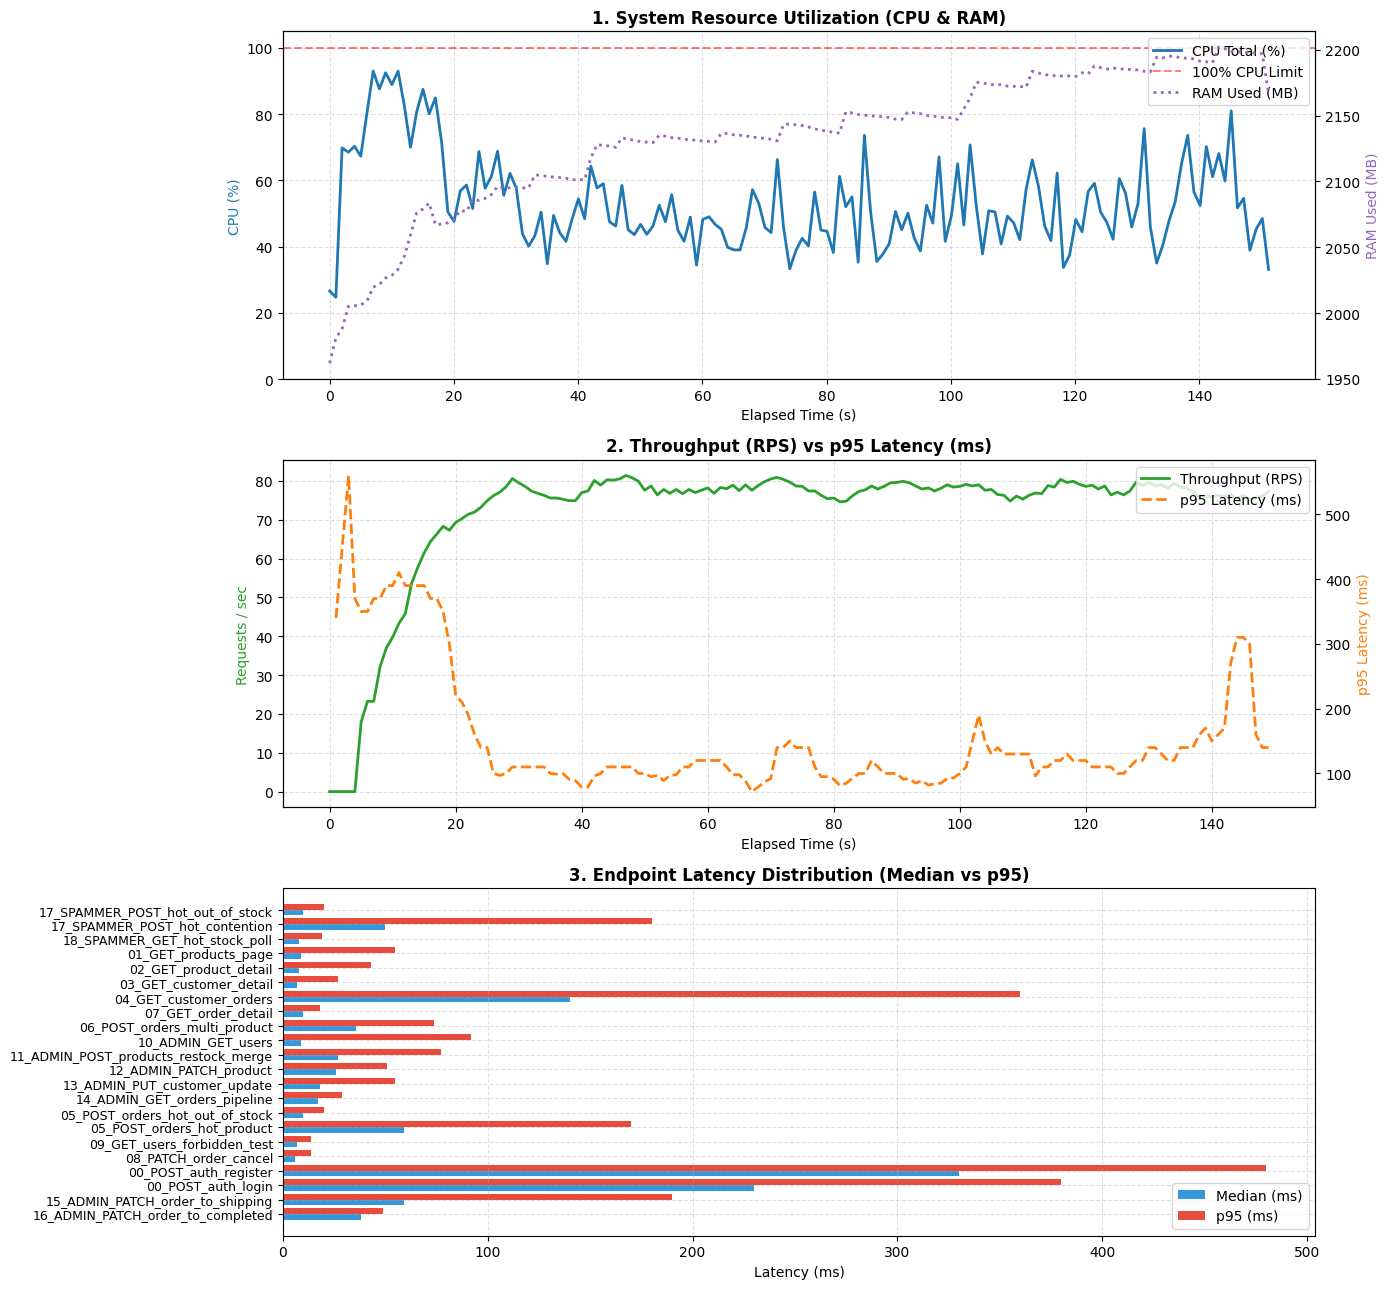

Báo cáo biểu đồ hiệu năng đã lưu tại /kaggle/working/kaggle_load_benchmark.png


In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt

metrics_df = pd.DataFrame(system_metrics)
if not metrics_df.empty:
    metrics_df["elapsed_sec"] = metrics_df["timestamp"] - metrics_df["timestamp"].min()

stats_file = "/kaggle/working/kaggle_load_results_stats.csv"
if os.path.exists(stats_file):
    stats_df = pd.read_csv(stats_file)
    display_cols = [c for c in ["Type", "Name", "Request Count", "Failure Count", "Median Response Time", "95%", "99%", "Requests/s"] if c in stats_df.columns]
    print("Bảng thống kê chi tiết các Endpoint:")
    display(stats_df[display_cols])

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 13), sharex=False)

# 1. System Resource (CPU & RAM)
if not metrics_df.empty:
    ax1.plot(metrics_df["elapsed_sec"], metrics_df["cpu_total_pct"], label="CPU Total (%)", color="#1f77b4", linewidth=2.0)
    ax1.axhline(100, color="red", linestyle="--", alpha=0.5, label="100% CPU Limit")
    ax1.set_title("1. System Resource Utilization (CPU & RAM)", fontsize=12, fontweight="bold")
    ax1.set_xlabel("Elapsed Time (s)")
    ax1.set_ylabel("CPU (%)", color="#1f77b4")
    ax1.set_ylim(0, 105)
    ax1.grid(True, linestyle="--", alpha=0.4)

    ax1_ram = ax1.twinx()
    ax1_ram.plot(metrics_df["elapsed_sec"], metrics_df["ram_used_mb"], label="RAM Used (MB)", color="#9467bd", linestyle=":", linewidth=2.0)
    ax1_ram.set_ylabel("RAM Used (MB)", color="#9467bd")

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_ram.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

# 2. Throughput vs Latency (RPS & p95)
history_file = "/kaggle/working/kaggle_load_results_stats_history.csv"
if os.path.exists(history_file) and os.path.getsize(history_file) > 0:
    hist_df = pd.read_csv(history_file)
    if "Name" in hist_df.columns and "Aggregated" in hist_df["Name"].values:
        hist_df = hist_df[hist_df["Name"] == "Aggregated"].copy()

    time_col = "Timestamp" if "Timestamp" in hist_df.columns else hist_df.columns[0]
    hist_df["elapsed_sec"] = hist_df[time_col] - hist_df[time_col].min()

    rps_col = next((c for c in ["Requests/s", "Total Requests/s", "Current RPS", "Requests/sec"] if c in hist_df.columns), None)
    p95_col = next((c for c in ["95%", "95%tile", "Total 95%"] if c in hist_df.columns), None)

    if rps_col:
        ax2.plot(hist_df["elapsed_sec"], hist_df[rps_col], color="#2ca02c", label="Throughput (RPS)", linewidth=2.0)
        ax2.set_ylabel("Requests / sec", color="#2ca02c")

    if p95_col:
        ax2_twin = ax2.twinx()
        ax2_twin.plot(hist_df["elapsed_sec"], hist_df[p95_col], color="#ff7f0e", linestyle="--", label="p95 Latency (ms)", linewidth=2.0)
        ax2_twin.set_ylabel("p95 Latency (ms)", color="#ff7f0e")

    ax2.set_title("2. Throughput (RPS) vs p95 Latency (ms)", fontsize=12, fontweight="bold")
    ax2.set_xlabel("Elapsed Time (s)")
    ax2.grid(True, linestyle="--", alpha=0.4)
    lines_a2, labels_a2 = ax2.get_legend_handles_labels()
    lines_b2, labels_b2 = ax2_twin.get_legend_handles_labels()
    ax2.legend(lines_a2 + lines_b2, labels_a2 + labels_b2, loc="upper right")

# 3. Endpoint Latency Comparison (Median vs P95)
if os.path.exists(stats_file):
    ep_df = pd.read_csv(stats_file)
    ep_df = ep_df[~ep_df["Name"].isin(["Aggregated", "Total"])].copy()
    ep_df = ep_df.sort_values(by="Request Count", ascending=True)

    y_pos = range(len(ep_df))
    ax3.barh([y - 0.2 for y in y_pos], ep_df["Median Response Time"], height=0.4, label="Median (ms)", color="#3498db")
    if "95%" in ep_df.columns:
        ax3.barh([y + 0.2 for y in y_pos], ep_df["95%"], height=0.4, label="p95 (ms)", color="#e74c3c")
    ax3.set_yticks(y_pos)
    ax3.set_yticklabels(ep_df["Name"], fontsize=9)
    ax3.set_xlabel("Latency (ms)")
    ax3.set_title("3. Endpoint Latency Distribution (Median vs p95)", fontsize=12, fontweight="bold")
    ax3.legend(loc="lower right")
    ax3.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("/kaggle/working/kaggle_load_benchmark.png", dpi=150)
plt.show()
print("Báo cáo biểu đồ hiệu năng đã lưu tại /kaggle/working/kaggle_load_benchmark.png")